# Revision checks (analytics-4589312): Prof. Abouali's focused checks

This notebook does **not** repeat the 120 model runs. It rebuilds the same split and cleaning (Cells 1–5, identical to `revision_rerun.ipynb`), then runs the checks:

| Cell | Check | Priority |
|---|---|---|
| 1–5 | Same setup as the rerun (install, settings, split + training-only cleaning, feature sets, models) | |
| C1 | Processing steps, counts, and proof that every filter, cap and scaler uses training data only | |
| C2 | No overlap between train / validation / test (and held-out-block tests); saves record IDs | **High** |
| C3 | Boundary-gap test: gaps between train, validation and test (training-only selected features) | **High** |
| C4 | Errors near the ends of capture blocks (stress test) | **High** |
| C5 | Training-only feature selection as the main result | **High** |
| C6 | Session information: is there any record that the blocks are separate sessions? | |
| C7 | Statistics: same test set across seeds; uncertainty that respects neighbouring records | |
| C10 | Reproducibility package (files + README) | |
| Last | Zip and download everything | |

Check 8 (LLM evaluation) is a separate notebook. Check 9 (efficiency) is not needed because the "lightweight" claim is being withdrawn.

**Before running:** Runtime → Change runtime type → **T4 GPU**. Upload **`Train_Test_Windows_10.csv`** and **`rerun_results.zip`** (from the first run) in the Files panel. Optional for C6: the full TON_IoT `windows10_dataset.csv` if you can download it.

In [1]:
import os
os.environ.setdefault('RERUN_OUT', '/content/checks_results')

# Cell 1: install (run once per Colab session)
!pip -q install pytorch-tabnet==4.1.0 rtdl_revisiting_models==0.0.2
import sklearn, torch, xgboost, lightgbm
print('sklearn', sklearn.__version__, '| torch', torch.__version__, '| xgboost', xgboost.__version__,
      '| lightgbm', lightgbm.__version__, '| GPU:', torch.cuda.is_available())

sklearn 1.6.1 | torch 2.11.0+cu130 | xgboost 3.4.1 | lightgbm 4.6.0 | GPU: True


In [2]:
# Cell 2: settings. Fixed BEFORE looking at any new results; do not change them afterwards.
import glob, os, json, time, copy, random, pickle, warnings
import numpy as np, pandas as pd, torch
warnings.filterwarnings('ignore')

_found = (glob.glob('/content/**/Train_Test_Windows_10*.csv', recursive=True)
          + glob.glob('/Train_Test_Windows_10*.csv'))
DATA_PATH = os.environ.get('W10_PATH') or (_found[0] if _found else None)
assert DATA_PATH, 'Upload Train_Test_Windows_10.csv in the Colab Files panel first.'
OUT = os.environ.get('RERUN_OUT', '/content/rerun_results'); os.makedirs(OUT, exist_ok=True)
print('Data file:', DATA_PATH, '| results folder:', OUT)

SEEDS = [42, 43, 44, 45, 46]            # prespecified seeds
TRAIN_FRAC, VAL_FRAC, GAP_FRAC = 0.70, 0.10, 0.0   # per class, in record order: 70% train | 10% val | 20% test (agreed with the professors)
NZV_THR, CAP_Q, CORR_THR = 0.95, 0.99, 0.95
FT_EPOCHS, TABNET_MAX_EPOCHS, TABNET_PATIENCE, BATCH = 50, 100, 15, 1024   # Table 9 values

FEATURES_9 = [
    'Memory Cache Bytes Peak',
    'Memory System Driver Resident Bytes',
    'Memory Pool Paged Resident Bytes',
    'LogicalDisk(_Total) pct_ Free Space',
    'Network_I(Intel R _82574L_GNC) Packets Sent Unicast sec',
    'Network_I(Intel R _82574L_GNC) Packets Sent sec',
    'Network_I(Intel R _82574L_GNC) Bytes Sent sec',
    'Process_IO Read_Operations_sec',
    'Process_IO_Write Operations_sec',
]
MCL = 'Memory Commit Limit'
FINGERPRINT_PATTERNS = ['TCP_APS', 'Standby Cache Lifetime', 'Free System Page Table Entries']  # the 3 removed by hand in the paper
F_PERCENTILE = 60                        # paper's F-statistic cutoff, now applied to training data only

MODELS = ['LR', 'DT', 'RF', 'XGB', 'LGBM', 'MLP', 'TabNet', 'FT']
CONFIGS = ['9', '10', 'reselect']
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

if os.environ.get('SMOKE') == '1':       # quick test mode, never set in Colab
    SEEDS, FT_EPOCHS, TABNET_MAX_EPOCHS = [42, 43], 2, 3

def norm(s):   # compare column names ignoring spaces, underscores and case
    return ''.join(ch for ch in str(s).lower() if ch.isalnum())

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

json.dump(dict(SEEDS=SEEDS, TRAIN_FRAC=TRAIN_FRAC, VAL_FRAC=VAL_FRAC, GAP_FRAC=GAP_FRAC, NZV_THR=NZV_THR, CAP_Q=CAP_Q,
               CORR_THR=CORR_THR, FT_EPOCHS=FT_EPOCHS, TABNET_MAX_EPOCHS=TABNET_MAX_EPOCHS,
               TABNET_PATIENCE=TABNET_PATIENCE, BATCH=BATCH, FEATURES_9=FEATURES_9, MCL=MCL,
               F_PERCENTILE=F_PERCENTILE, DEVICE=DEVICE), open(f'{OUT}/settings.json', 'w'), indent=2)

Data file: /content/Train_Test_Windows_10.csv | results folder: /content/checks_results


In [3]:
# Cell 3: load, clean, split. Every learned statistic (variance filter, caps, correlation) uses TRAINING rows only.
from sklearn.preprocessing import LabelEncoder
acct = []
def log(step, rows, cols, note=''):
    acct.append(dict(step=step, rows=rows, columns=cols, note=note))

raw = pd.read_csv(DATA_PATH, low_memory=False)
log('Raw CSV loaded', len(raw), raw.shape[1])
df = raw.copy()
FEATS_ALL = [c for c in df.columns if c not in ('label', 'type')]
empty_before = int(df[FEATS_ALL].isna().sum().sum())
for c in FEATS_ALL:
    df[c] = pd.to_numeric(df[c], errors='coerce')
n_bad = int(df[FEATS_ALL].isna().sum().sum()) - empty_before
log('Text columns converted to numeric', len(df), df.shape[1],
    f'{n_bad} unparseable cells -> NaN ({empty_before} empty cells before conversion)')

df['type'] = df['type'].astype(str).str.strip().str.lower()
df = df[df['type'] != 'mitm'].copy()          # original row index kept = record order
log('MITM removed', len(df), df.shape[1], f'{len(raw) - len(df)} rows')
n_dup = int(df.duplicated().sum())
if n_dup: df = df.drop_duplicates()
log('Duplicate rows', len(df), df.shape[1], f'{n_dup} duplicates removed')
n_neg = int((df[FEATS_ALL] < 0).any(axis=1).sum())
log('Negative-value rows checked', len(df), df.shape[1], f'{n_neg} rows with negatives (kept)')
df[FEATS_ALL] = df[FEATS_ALL].fillna(0)      # constant fill (0), nothing learned from the data, so no test information
log('Targets separated (label, type)', len(df), len(FEATS_ALL), 'NaN filled with constant 0')

# Per-class chronological split
def chrono_split(idx):
    n = len(idx); ntr = int(TRAIN_FRAC * n); nva = int(round(VAL_FRAC * n)); gap = int(round(GAP_FRAC * n))
    return idx[:ntr], idx[ntr + gap: ntr + gap + nva], idx[ntr + 2 * gap + nva:]   # test = the rest (about 20%)

parts, sizes = {'train': [], 'val': [], 'test': []}, {}
for c in sorted(df['type'].unique()):
    idx = np.sort(df.index[df['type'] == c].values)
    tr, va, te = chrono_split(idx)
    parts['train'] += list(tr); parts['val'] += list(va); parts['test'] += list(te)
    sizes[c] = dict(train=len(tr), val=len(va), test=len(te), gap_dropped=len(idx) - len(tr) - len(va) - len(te))
TR, VA, TE = (np.array(sorted(parts[k])) for k in ('train', 'val', 'test'))

# Train-only cleaning
train = df.loc[TR, FEATS_ALL]
NZV = [c for c in FEATS_ALL if train[c].value_counts(normalize=True).iloc[0] > NZV_THR]
KEEP = [c for c in FEATS_ALL if c not in NZV]
log('Near-zero-variance removed (fit on train)', len(TR), len(KEEP), f'{len(NZV)} columns')
CAPS = df.loc[TR, KEEP].quantile(CAP_Q)
X = df[KEEP].clip(upper=CAPS, axis=1)        # caps from train, applied to train / val / test
log('99th-percentile caps (fit on train, applied to all)', len(TR), len(KEEP), 'no rows removed')
corr = X.loc[TR].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
CORR_DROP = [c for c in upper.columns if (upper[c] > CORR_THR).any()]
ELIGIBLE = [c for c in KEEP if c not in CORR_DROP]
log('Correlated columns removed (fit on train)', len(TR), len(ELIGIBLE), f'{len(CORR_DROP)} columns, |r|>{CORR_THR}')

le = LabelEncoder().fit(df['type'])
CLASSES = list(le.classes_)
y = pd.Series(le.transform(df['type']), index=df.index)
y_tr, y_va, y_te = y.loc[TR].values, y.loc[VA].values, y.loc[TE].values

acct = pd.DataFrame(acct); split_tab = pd.DataFrame(sizes).T
print(acct.to_string(index=False)); print('\nPer-class split sizes:\n', split_tab.to_string())
print(f'\nTotals: train {len(TR)}, val {len(VA)}, test {len(TE)} | classes {CLASSES}')
print(f'Eligible features after train-only cleaning: {len(ELIGIBLE)}')
acct.to_csv(f'{OUT}/data_accounting.csv', index=False); split_tab.to_csv(f'{OUT}/split_sizes.csv')
json.dump(dict(train=TR.tolist(), val=VA.tolist(), test=TE.tolist(), classes=CLASSES, nzv=NZV,
               corr_drop=CORR_DROP, eligible=ELIGIBLE), open(f'{OUT}/split_and_cleaning.json', 'w'))

                                               step  rows  columns                                                            note
                                     Raw CSV loaded 21104      126                                                                
                  Text columns converted to numeric 21104      126 1896 unparseable cells -> NaN (0 empty cells before conversion)
                                       MITM removed 21089      126                                                         15 rows
                                     Duplicate rows 21089      126                                            0 duplicates removed
                        Negative-value rows checked 21089      126                                    0 rows with negatives (kept)
                    Targets separated (label, type) 21089      124                                      NaN filled with constant 0
          Near-zero-variance removed (fit on train) 14759      104                 

In [4]:
# Cell 4: feature configurations
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import f_classif

missing = [f for f in FEATURES_9 + [MCL] if f not in X.columns]
assert not missing, f'Not found after cleaning (check names / NZV filter): {missing}'
print('Paper features dropped by the train-only correlation filter:',
      [f for f in FEATURES_9 + [MCL] if f in CORR_DROP] or 'none',
      '\n(They are kept in configs "9" and "10" because those sets are pre-specified.)')

# Train-only rerun of the documented selection procedure (paper Section 4.4):
# RF importance -> top 20 -> drop the 3 hand-flagged fingerprint features -> drop F >= 60th percentile -> drop MCL
rf_sel = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1).fit(X.loc[TR, ELIGIBLE], y_tr)
imp = pd.Series(rf_sel.feature_importances_, index=ELIGIBLE).sort_values(ascending=False)
top20 = list(imp.index[:20])
fp = [f for f in top20 if any(norm(p) in norm(f) for p in FINGERPRINT_PATTERNS)]
cand = [f for f in top20 if f not in fp]
Fv, _ = f_classif(X.loc[TR, cand], y_tr)
Fs = pd.Series(np.nan_to_num(Fv, nan=0.0), index=cand).sort_values(ascending=False)
F_CUT = float(np.percentile(Fs.values, F_PERCENTILE))
f_drop = list(Fs[Fs >= F_CUT].index)
RESELECT = [f for f in cand if f not in f_drop and f != MCL]

FEATURE_SETS = {'9': FEATURES_9, '10': FEATURES_9 + [MCL], 'reselect': RESELECT}
sel_report = pd.DataFrame({'rf_importance': imp.loc[top20], 'F_train': Fs.reindex(top20)})
sel_report['decision'] = ['fingerprint (hand-flagged)' if f in fp else f'F >= {F_CUT:.1f}' if f in f_drop
                          else 'MCL (manual rule)' if f == MCL else 'kept' for f in top20]
print(sel_report.to_string())
print(f'\nTrain-only reselection kept {len(RESELECT)} features:', RESELECT)
overlap = sorted(set(RESELECT) & set(FEATURES_9))
print(f'Overlap with the paper\'s 9: {len(overlap)} ->', overlap)
sel_report.to_csv(f'{OUT}/reselection_report.csv')
json.dump(FEATURE_SETS, open(f'{OUT}/feature_sets.json', 'w'), indent=2)

Paper features dropped by the train-only correlation filter: ['Network_I(Intel R _82574L_GNC) Packets Sent sec'] 
(They are kept in configs "9" and "10" because those sets are pre-specified.)
                                                         rf_importance       F_train                    decision
Process_Pool_Paged Bytes                                      0.101407   6431.780826                 F >= 2337.5
Process_Virtual_Bytes Peak                                    0.094386  38623.509966                 F >= 2337.5
Network_I(Intel R _82574L_GNC)TCP_APS                         0.084905           NaN  fingerprint (hand-flagged)
Memory Long-Term Average Standby Cache Lifetime (s)           0.066249           NaN  fingerprint (hand-flagged)
Memory System Driver Total Bytes                              0.061573  29591.359631                 F >= 2337.5
Memory Free System Page Table Entries                         0.054724           NaN  fingerprint (hand-flagged)
Process_Pool Nonp

In [6]:
# Cell 5: models. Settings from Table 9; small grids tuned on the VALIDATION set (macro-F1); test set never used here.
import torch.nn.functional as Fnn
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score
from xgboost import XGBClassifier
import lightgbm as lgb
from pytorch_tabnet.tab_model import TabNetClassifier
from rtdl_revisiting_models import FTTransformer

def mf1(a, b): return f1_score(a, b, average='macro')

def size_kb(obj):
    try: return len(pickle.dumps(obj)) / 1024
    except Exception: return np.nan

def grid_fit(make, grid, Xtr, ytr, Xva, yva, fit_kw=None):
    best = None
    for params in grid:
        m = make(**params)
        m.fit(Xtr, ytr, **(fit_kw(params) if fit_kw else {}))
        s = mf1(yva, m.predict(Xva))
        if best is None or s > best[0]: best = (s, params, m)
    return best[2], best[1]

def torch_predict(model, Xn):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(Xn), 4096):
            out.append(model(torch.tensor(Xn[i:i + 4096], dtype=torch.float32, device=DEVICE), None).argmax(1).cpu().numpy())
    return np.concatenate(out)

def train_ft(Xtr, ytr, Xva, yva, seed):
    set_seed(seed)
    model = FTTransformer(n_cont_features=Xtr.shape[1], cat_cardinalities=[], d_out=len(CLASSES),
                          **FTTransformer.get_default_kwargs()).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-5)
    xt = torch.tensor(Xtr, dtype=torch.float32, device=DEVICE); yt = torch.tensor(ytr, dtype=torch.long, device=DEVICE)
    g = torch.Generator().manual_seed(seed); best = (-1, None, 0)
    for ep in range(FT_EPOCHS):
        model.train()
        for b in torch.randperm(len(xt), generator=g).split(BATCH):
            b = b.to(DEVICE); opt.zero_grad()
            Fnn.cross_entropy(model(xt[b], None), yt[b]).backward(); opt.step()
        s = mf1(yva, torch_predict(model, Xva))
        if s > best[0]: best = (s, copy.deepcopy(model.state_dict()), ep + 1)
    model.load_state_dict(best[1])
    return model, {'best_epoch': best[2]}

def run_model(name, Xtr, ytr, Xva, yva, seed):
    """Returns (fitted model, chosen params, predict function)."""
    if name == 'LR':
        m, p = grid_fit(lambda **k: LogisticRegression(max_iter=1000, **k), [dict(C=c) for c in (0.1, 1, 10)], Xtr, ytr, Xva, yva)
    elif name == 'DT':
        m, p = grid_fit(lambda **k: DecisionTreeClassifier(random_state=seed, **k),
                        [dict(max_depth=d, min_samples_leaf=l) for d in (None, 10, 20) for l in (1, 5)], Xtr, ytr, Xva, yva)
    elif name == 'RF':
        m, p = grid_fit(lambda **k: RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=-1, **k),
                        [dict(max_depth=d, min_samples_leaf=l) for d in (None, 20) for l in (1, 2)], Xtr, ytr, Xva, yva)
    elif name == 'XGB':
        m, p = grid_fit(lambda **k: XGBClassifier(n_estimators=1000, learning_rate=0.05, subsample=0.9, colsample_bytree=0.9,
                                                  tree_method='hist', early_stopping_rounds=50, eval_metric='mlogloss',
                                                  random_state=seed, n_jobs=-1, **k),
                        [dict(max_depth=d) for d in (4, 6, 8)], Xtr, ytr, Xva, yva,
                        fit_kw=lambda _: dict(eval_set=[(Xva, yva)], verbose=False))
        p = dict(p, best_iteration=int(m.best_iteration))
    elif name == 'LGBM':
        m, p = grid_fit(lambda **k: lgb.LGBMClassifier(n_estimators=2000, learning_rate=0.05, random_state=seed, verbose=-1, n_jobs=-1, **k),
                        [dict(num_leaves=n) for n in (15, 31, 63)], Xtr, ytr, Xva, yva,
                        fit_kw=lambda _: dict(eval_set=[(Xva, yva)], callbacks=[lgb.early_stopping(50, verbose=False)]))
        p = dict(p, best_iteration=int(m.best_iteration_))
    elif name == 'MLP':   # (64, 32) ReLU, 500 iterations, early stopping on a split of the TRAINING data (Table 9)
        m, p = grid_fit(lambda **k: MLPClassifier(hidden_layer_sizes=(64, 32), activation='relu', max_iter=500,
                                                  early_stopping=True, random_state=seed, **k),
                        [dict(alpha=a) for a in (1e-4, 1e-3)], Xtr, ytr, Xva, yva)
    elif name == 'TabNet':  # early stopping now monitors the VALIDATION set (was the test set)
        set_seed(seed)
        m = TabNetClassifier(seed=seed, verbose=0, device_name=DEVICE)
        m.fit(Xtr.astype(np.float32), ytr, eval_set=[(Xva.astype(np.float32), yva)], eval_name=['val'],
              eval_metric=['logloss'], max_epochs=TABNET_MAX_EPOCHS, patience=TABNET_PATIENCE,
              batch_size=BATCH, virtual_batch_size=128)
        p = {'best_epoch': int(m.best_epoch)}
        return m, p, lambda Z: m.predict(Z.astype(np.float32))
    elif name == 'FT':      # 50 epochs as in Table 9; the epoch with the best VALIDATION macro-F1 is kept
        m, p = train_ft(Xtr, ytr, Xva, yva, seed)
        return m, p, lambda Z: torch_predict(m, Z)
    else:
        raise ValueError(name)
    return m, p, m.predict

def n_params(m):
    if isinstance(m, torch.nn.Module): return sum(t.numel() for t in m.parameters())
    if hasattr(m, 'network'): return sum(t.numel() for t in m.network.parameters())
    return np.nan
print('Models ready on', DEVICE)

Models ready on cuda


In [7]:
# Check helpers: one function that re-fits EVERY learned step from a given set of training rows.
from sklearn.preprocessing import StandardScaler
import zipfile

def fit_pipeline(frame, tr_rows):
    tr_rows = np.asarray(tr_rows); ytr = y.loc[tr_rows].values
    t = frame.loc[tr_rows, FEATS_ALL]
    nzv = [c for c in FEATS_ALL if t[c].value_counts(normalize=True).iloc[0] > NZV_THR]
    keep = [c for c in FEATS_ALL if c not in nzv]
    caps = frame.loc[tr_rows, keep].quantile(CAP_Q)
    Xf = frame[keep].clip(upper=caps, axis=1)
    cr = Xf.loc[tr_rows].corr().abs()
    up = cr.where(np.triu(np.ones(cr.shape), k=1).astype(bool))
    cdrop = [c for c in up.columns if (up[c] > CORR_THR).any()]
    elig = [c for c in keep if c not in cdrop]
    rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1).fit(Xf.loc[tr_rows, elig], ytr)
    imp = pd.Series(rf.feature_importances_, index=elig).sort_values(ascending=False)
    t20 = list(imp.index[:20])
    fpl = [f for f in t20 if any(norm(p) in norm(f) for p in FINGERPRINT_PATTERNS)]
    cnd = [f for f in t20 if f not in fpl]
    Fv, _ = f_classif(Xf.loc[tr_rows, cnd], ytr)
    Fser = pd.Series(np.nan_to_num(Fv, nan=0.0), index=cnd)
    cut = float(np.percentile(Fser.values, F_PERCENTILE))
    resel = [f for f in cnd if Fser[f] < cut and f != MCL]
    sets = {'9': FEATURES_9, '10': FEATURES_9 + [MCL], 'reselect': resel}
    scalers = {k: StandardScaler().fit(Xf.loc[tr_rows, v].values) for k, v in sets.items()}
    return dict(nzv=nzv, keep=keep, caps=caps, X=Xf, cdrop=cdrop, elig=elig, top20=t20, resel=resel,
                F_cut=cut, sets=sets, scalers=scalers)

def segments(c):   # contiguous blocks of rows for one class, in the original file order
    idx = np.sort(df.index[df['type'] == c].values)
    return np.split(idx, np.where(np.diff(idx) != 1)[0] + 1)
SEG = {c: segments(c) for c in CLASSES}
BLOCK_ID, POS_IN_BLOCK, FROM_END = {}, {}, {}
for c, segs in SEG.items():
    for k, s in enumerate(segs):
        for j, i in enumerate(s):
            BLOCK_ID[i] = f'{c}-{k+1}'; POS_IN_BLOCK[i] = j / max(len(s) - 1, 1); FROM_END[i] = len(s) - 1 - j

# Earlier results (rerun_results.zip) for Checks 4, 5, 7
PREV = os.environ.get('PREV_DIR', '/content/prev_results')
_zp = [z for z in glob.glob('/content/**/rerun_results*.zip', recursive=True)]
if _zp and not os.path.exists(f'{PREV}/test_predictions.npz'):
    zipfile.ZipFile(_zp[0]).extractall(PREV)
HAVE_PREV = os.path.exists(f'{PREV}/test_predictions.npz')
print('Earlier rerun results found:', HAVE_PREV, '| blocks per class:', {c: len(v) for c, v in SEG.items()})

Earlier rerun results found: True | blocks per class: {'ddos': 1, 'dos': 3, 'injection': 1, 'normal': 2, 'password': 1, 'scanning': 1, 'xss': 1}


In [8]:
# C1: processing steps, counts, and proof of training-only fitting
print(acct.to_string(index=False))
expected = {'Raw CSV loaded': (21104, 126), 'MITM removed': (21089, 126), 'Targets separated (label, type)': (21089, 124),
            'Near-zero-variance removed (fit on train)': (14759, 104), 'Correlated columns removed (fit on train)': (14759, 78)}
print('\nCounts:')
for step, (r, c) in expected.items():
    row = acct[acct.step == step].iloc[0]
    print(f"  {'OK      ' if (row.rows, row.columns) == (r, c) else 'MISMATCH'} {step}: {row.rows} rows, {row.columns} columns (expected {r}, {c})")

base = fit_pipeline(df, TR)
same_as_notebook = dict(near_constant=base['nzv'] == NZV, caps=bool(np.allclose(base['caps'], CAPS)),
                        correlation=base['cdrop'] == CORR_DROP, reselection=base['resel'] == RESELECT)
print('\nPipeline function reproduces Cells 3-4:', same_as_notebook)

# Tamper test: scramble every VALIDATION and TEST value, refit, and confirm that nothing learned changes.
rng = np.random.default_rng(0); nt = np.concatenate([VA, TE])
tampered = df.copy()
tampered.loc[nt, FEATS_ALL] = (df.loc[nt, FEATS_ALL].values * rng.uniform(0.1, 10, (len(nt), len(FEATS_ALL)))
                               + rng.normal(0, 1e6, (len(nt), len(FEATS_ALL))))
alt = fit_pipeline(tampered, TR)
tamper = {
    'near-constant filter (20 columns)': alt['nzv'] == base['nzv'],
    '99th-percentile caps': bool(np.allclose(alt['caps'], base['caps'])),
    'correlation filter (26 columns)': alt['cdrop'] == base['cdrop'],
    'RF top-20 ranking': alt['top20'] == base['top20'],
    'F-statistic cutoff': np.isclose(alt['F_cut'], base['F_cut']),
    'reselected features': alt['resel'] == base['resel'],
    'scalers (all 3 feature sets)': all(np.allclose(alt['scalers'][k].mean_, base['scalers'][k].mean_) and
                                        np.allclose(alt['scalers'][k].scale_, base['scalers'][k].scale_) for k in base['sets']),
}
print('\nTamper test (validation + test values scrambled, pipeline refit):')
for k, v in tamper.items(): print(f"  {'UNCHANGED' if v else 'CHANGED  '}  {k}")
print('-> all learned steps depend on training rows only' if all(tamper.values()) else '-> WARNING: something uses non-training rows')
print('\nOrder of steps: text->numeric, MITM removal, duplicate/negative checks, constant fill (0), per-class 70/10/20 split,'
      '\n then fitted on train only: near-constant filter -> 99th-pct caps -> correlation filter -> RF top 20 -> fingerprint removal'
      '\n -> F >= 60th pct removal -> Memory Commit Limit removal -> standard scaling.')
print('\nFeature sets: "9" and "10" are fixed lists carried over from the earlier experiments (comparison only);'
      '\n "reselect" is chosen from training data only by the procedure above:', base['resel'])
pd.DataFrame([dict(check=k, passed=bool(v)) for k, v in {**same_as_notebook, **tamper}.items()]).to_csv(f'{OUT}/C1_training_only_checks.csv', index=False)

                                               step  rows  columns                                                            note
                                     Raw CSV loaded 21104      126                                                                
                  Text columns converted to numeric 21104      126 1896 unparseable cells -> NaN (0 empty cells before conversion)
                                       MITM removed 21089      126                                                         15 rows
                                     Duplicate rows 21089      126                                            0 duplicates removed
                        Negative-value rows checked 21089      126                                    0 rows with negatives (kept)
                    Targets separated (label, type) 21089      124                                      NaN filled with constant 0
          Near-zero-variance removed (fit on train) 14759      104                 

In [9]:
# C2: split verification + saved record IDs
part = pd.Series('gap/excluded', index=df.index); part.loc[TR] = 'train'; part.loc[VA] = 'val'; part.loc[TE] = 'test'
S = {'train': set(TR), 'val': set(VA), 'test': set(TE)}
res2 = {f'{a} ∩ {b}': len(S[a] & S[b]) for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')]}
res2['records covered'] = f"{len(S['train'] | S['val'] | S['test'])} of {len(df)}"
order_ok = {}
for c in CLASSES:
    tr_, va_, te_ = (np.intersect1d(P_, df.index[df['type'] == c]) for P_ in (TR, VA, TE))
    order_ok[c] = bool(tr_.max() < va_.min() and va_.max() < te_.min())
print('Overlaps:', res2); print('Within each class, train < val < test in record order:', order_ok)

def hash_rows(rows, cols): return set(pd.util.hash_pandas_object(df.loc[rows, cols].round(6), index=False))
def dup_count(cols, a, b):
    ha = hash_rows(a, cols)
    return int(pd.util.hash_pandas_object(df.loc[b, cols].round(6), index=False).isin(ha).sum())
print('\nTest records whose feature values exactly repeat a training record:')
print(f"  all 124 features: {dup_count(FEATS_ALL, TR, TE)} of {len(TE)}")
for k in ['9', 'reselect']:
    print(f"  feature set {k}: {dup_count(base['sets'][k], TR, TE)} of {len(TE)}")

ids = pd.DataFrame({'record_index': df.index, 'type': df['type'].values, 'partition': part.values,
                    'block': [BLOCK_ID[i] for i in df.index], 'position_in_block': [round(POS_IN_BLOCK[i], 4) for i in df.index]})
ids.to_csv(f'{OUT}/split_record_ids.csv', index=False)

# Held-out-block scenarios (same construction as rerun Cell 11)
rows = []; ok_all = True
for c in [c for c in CLASSES if len(SEG[c]) > 1]:
    for k in range(len(SEG[c])):
        own = np.sort(np.concatenate([s for j, s in enumerate(SEG[c]) if j != k])); n_va = max(1, int(0.15 * len(own)))
        tr_r = set(TR[y.loc[TR].values != CLASSES.index(c)]) | set(own[:-n_va])
        va_r = set(VA[y.loc[VA].values != CLASSES.index(c)]) | set(own[-n_va:])
        te_r = set(SEG[c][k]); name = f'{c}: hold out block {k+1}'
        ok = not (tr_r & va_r or tr_r & te_r or va_r & te_r)
        ok_all &= ok
        print(f"{name:28s} train {len(tr_r):6d} | val {len(va_r):5d} | test {len(te_r):5d} | no overlap: {ok}")
        rows += [(name, i, 'train') for i in sorted(tr_r)] + [(name, i, 'val') for i in sorted(va_r)] + [(name, i, 'test') for i in sorted(te_r)]
pd.DataFrame(rows, columns=['scenario', 'record_index', 'partition']).to_csv(f'{OUT}/heldout_block_record_ids.csv', index=False)
print('\nAll held-out-block scenarios free of overlap:', ok_all)
print('Saved: split_record_ids.csv, heldout_block_record_ids.csv (record_index = 0-based row in the raw CSV, header excluded)')

Overlaps: {'train ∩ val': 0, 'train ∩ test': 0, 'val ∩ test': 0, 'records covered': '21089 of 21089'}
Within each class, train < val < test in record order: {'ddos': True, 'dos': True, 'injection': True, 'normal': True, 'password': True, 'scanning': True, 'xss': True}

Test records whose feature values exactly repeat a training record:
  all 124 features: 0 of 4221
  feature set 9: 0 of 4221
  feature set reselect: 0 of 4221
dos: hold out block 1        train  14796 | val  2128 | test    50 | no overlap: True
dos: hold out block 2        train  14740 | val  2118 | test   116 | no overlap: True
dos: hold out block 3        train  14534 | val  2081 | test   359 | no overlap: True
normal: hold out block 1     train  15298 | val  2439 | test  1131 | no overlap: True
normal: hold out block 2     train   8721 | val  1278 | test  8869 | no overlap: True

All held-out-block scenarios free of overlap: True
Saved: split_record_ids.csv, heldout_block_record_ids.csv (record_index = 0-based row in 

In [10]:
# C3: boundary-gap test. The TEST set stays exactly the same; a gap of g% of each class is removed
# between train|val and val|test, so the nearest training/validation records are pushed away from the test records.
# The whole training-only pipeline (filters, caps, reselection, scaling) is refit for every gap.
GAPS = [0.0, 0.01, 0.02, 0.05]
GAP_MODELS, GAP_SEEDS = ['RF', 'XGB', 'LGBM', 'MLP', 'FT'], SEEDS[:3]

def gap_split(g):
    tr, va, te = [], [], []
    for c in CLASSES:
        idx = np.sort(df.index[df['type'] == c].values); n = len(idx)
        nva = int(round(VAL_FRAC * n)); nte = n - int(TRAIN_FRAC * n) - nva; gap = int(round(g * n))
        te += list(idx[n - nte:]); va += list(idx[n - nte - gap - nva: n - nte - gap]); tr += list(idx[: n - nte - 2 * gap - nva])
    return np.array(sorted(tr)), np.array(sorted(va)), np.array(sorted(te))

G_CSV, G_NPZ = f'{OUT}/C3_gap_results.csv', f'{OUT}/C3_gap_predictions.npz'
gres = pd.read_csv(G_CSV).to_dict('records') if os.path.exists(G_CSV) else []
gpred = dict(np.load(G_NPZ)) if os.path.exists(G_NPZ) else {}
gdone = {(float(r['gap']), int(r['seed']), r['model']) for r in gres}
gfeats = {}
for g in GAPS:
    tr_g, va_g, te_g = gap_split(g)
    assert np.array_equal(te_g, TE), 'test set must be identical for every gap'
    fp = fit_pipeline(df, tr_g); feats = fp['resel']; gfeats[g] = feats
    sc = StandardScaler().fit(fp['X'].loc[tr_g, feats].values)
    Xtr_, Xva_, Xte_ = (sc.transform(fp['X'].loc[r, feats].values) for r in (tr_g, va_g, te_g))
    ytr_, yva_ = y.loc[tr_g].values, y.loc[va_g].values
    for seed in GAP_SEEDS:
        for name in GAP_MODELS:
            if (g, seed, name) in gdone: continue
            m, params, predict = run_model(name, Xtr_, ytr_, Xva_, yva_, seed); p = predict(Xte_)
            row = dict(gap=g, train_n=len(tr_g), val_n=len(va_g), seed=seed, model=name,
                       test_acc=accuracy_score(y_te, p), test_macro_f1=mf1(y_te, p),
                       **{f'recall_{c}': float((p[y_te == i] == i).mean()) for i, c in enumerate(CLASSES)})
            gres.append(row); gpred[f'{g}|{seed}|{name}'] = p.astype(np.int8)
            pd.DataFrame(gres).to_csv(G_CSV, index=False); np.savez_compressed(G_NPZ, **gpred)
            print(f"gap {g:.0%} | seed {seed} | {name:5s} acc {row['test_acc']*100:6.2f}%  F1 {row['test_macro_f1']:.3f}")

gr = pd.DataFrame(gres)
tab = gr.groupby(['model', 'gap'])['test_acc'].agg(lambda s: f'{100*s.mean():.2f} ± {100*s.std(ddof=1):.2f}').unstack('gap')
print('\nTest accuracy (%) by gap between partitions (same test records; mean ± SD over seeds):'); print(tab.to_string())
print('\nMacro-F1 by gap:'); print(gr.groupby(['model', 'gap'])['test_macro_f1'].mean().unstack('gap').round(3).to_string())
print('\nRecall of the two weakest classes by gap (mean over models and seeds):')
print(gr.groupby('gap')[['recall_ddos', 'recall_scanning']].mean().round(3).to_string())
print('\nTraining-only selected features per gap (stability):')
for g, f in gfeats.items():
    j = len(set(f) & set(gfeats[0.0])) / len(set(f) | set(gfeats[0.0]))
    print(f'  gap {g:.0%}: {len(f)} features, overlap with gap 0% (Jaccard) {j:.2f}')
pd.DataFrame([dict(gap=g, features='; '.join(f)) for g, f in gfeats.items()]).to_csv(f'{OUT}/C3_selected_features_by_gap.csv', index=False)

# Where in the test block do errors happen? (gap 0%, all models and seeds)
rel = np.empty(len(TE))
for i, c in enumerate(CLASSES):
    m_ = y_te == i; rel[m_] = np.linspace(0, 1, m_.sum())
dec = np.minimum((rel * 5).astype(int), 4)
err = np.mean([(gpred[f'0.0|{s}|{m}'] != y_te) for s in GAP_SEEDS for m in GAP_MODELS], axis=0)
pos = pd.Series(err).groupby(dec).mean() * 100
pos.index = ['first 20% (next to validation)', '20-40%', '40-60%', '60-80%', 'last 20% (end of block)']
print('\nError rate (%) by position inside each class\'s test records (gap 0%):'); print(pos.round(2).to_string())
pos.to_csv(f'{OUT}/C3_error_rate_by_test_position.csv')

gap 0% | seed 42 | RF    acc  99.69%  F1 0.988
gap 0% | seed 42 | XGB   acc  99.67%  F1 0.988
gap 0% | seed 42 | LGBM  acc  97.16%  F1 0.976
gap 0% | seed 42 | MLP   acc  99.69%  F1 0.988
gap 0% | seed 42 | FT    acc  99.69%  F1 0.988
gap 0% | seed 43 | RF    acc  99.69%  F1 0.988
gap 0% | seed 43 | XGB   acc  99.67%  F1 0.988
gap 0% | seed 43 | LGBM  acc  97.16%  F1 0.976
gap 0% | seed 43 | MLP   acc  99.67%  F1 0.988
gap 0% | seed 43 | FT    acc  99.69%  F1 0.988
gap 0% | seed 44 | RF    acc  99.69%  F1 0.988
gap 0% | seed 44 | XGB   acc  99.67%  F1 0.988
gap 0% | seed 44 | LGBM  acc  97.16%  F1 0.976
gap 0% | seed 44 | MLP   acc  99.62%  F1 0.987
gap 0% | seed 44 | FT    acc  99.67%  F1 0.988
gap 1% | seed 42 | RF    acc  99.67%  F1 0.988
gap 1% | seed 42 | XGB   acc  99.67%  F1 0.988
gap 1% | seed 42 | LGBM  acc  97.51%  F1 0.978
gap 1% | seed 42 | MLP   acc  99.69%  F1 0.988
gap 1% | seed 42 | FT    acc  99.69%  F1 0.988
gap 1% | seed 43 | RF    acc  99.69%  F1 0.988
gap 1% | seed

Predictions from: rerun_results.zip (all 120 runs)

Mean errors per run, by true class (rows: config/model):
true              ddos    dos  normal  password  scanning
config   model                                           
10       DT        4.0    0.0     3.8       0.0      16.0
         FT        0.0    0.0     0.0       0.0      13.2
         LGBM     74.0    0.0     0.0       0.0      13.0
         LR        0.0    0.0     0.0       0.0      89.0
         MLP       0.0    0.0     1.0       0.0      13.0
         RF        9.8    0.0     0.0       0.0      12.0
         TabNet    0.0    0.0     1.4       0.0      13.0
         XGB       2.6    0.0     0.0       0.0      13.0
9        DT        4.0    0.0     4.4       0.0      16.0
         FT        8.6    0.0     1.0       1.2      13.6
         LGBM     87.0    0.0     0.0       0.0      13.0
         LR       13.0  106.0  1334.0       0.0      88.0
         MLP       0.0    0.0     1.8       0.0      13.0
         RF       31.

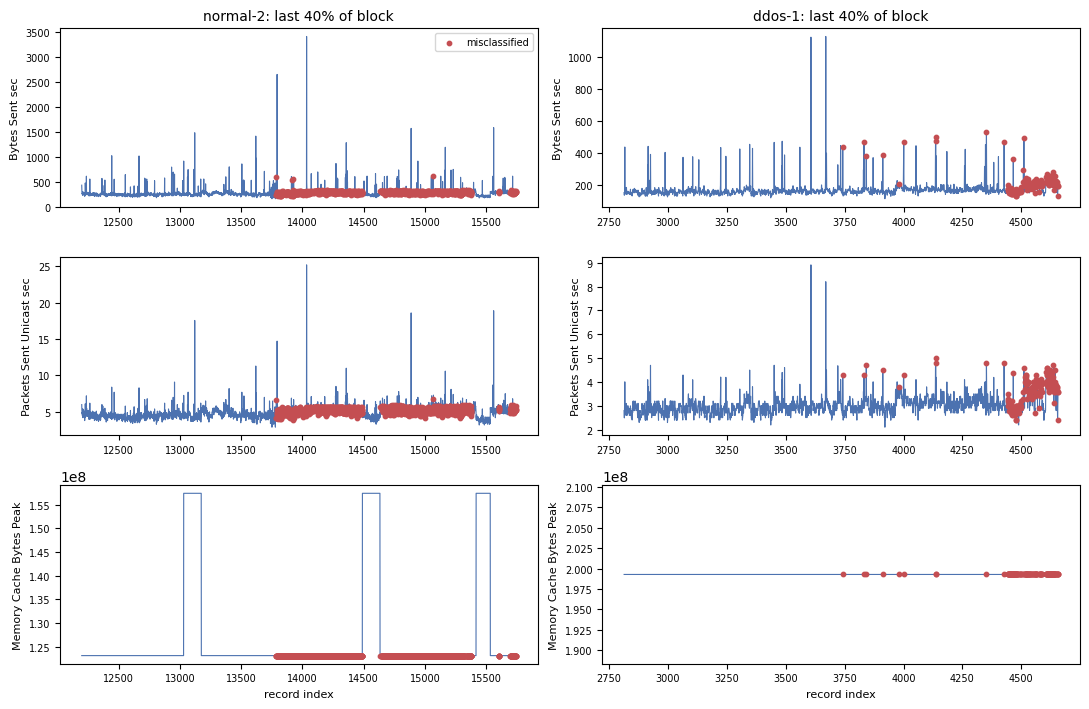

Note: this is a stress test of block ends, not evidence of independent-session performance.


In [11]:
# C4: errors near the ends of capture blocks (stress test; descriptive, does not change any model)
import matplotlib.pyplot as plt
if HAVE_PREV:
    Pp = dict(np.load(f'{PREV}/test_predictions.npz')); assert np.array_equal(np.load(f'{PREV}/test_index.npy'), TE), 'different test set'
    src = 'rerun_results.zip (all 120 runs)'
else:
    Pp = {f'reselect|{k.split("|")[1]}|{k.split("|")[2]}': v for k, v in np.load(f'{OUT}/C3_gap_predictions.npz').items() if k.startswith('0.0|')}
    src = 'Check 3, gap 0% (rerun_results.zip not found)'
print('Predictions from:', src)
er = []
for key, p in Pp.items():
    cfg, seed, model = key.split('|')
    for j in np.where(p != y_te)[0]:
        i = TE[j]; er.append(dict(config=cfg, seed=int(seed), model=model, record_index=int(i), true=CLASSES[y_te[j]],
                                  predicted=CLASSES[p[j]], block=BLOCK_ID[i], position_in_block=POS_IN_BLOCK[i], records_from_block_end=FROM_END[i]))
er = pd.DataFrame(er); er.to_csv(f'{OUT}/C4_all_test_errors.csv', index=False)
n_seeds = er.groupby(['config', 'model'])['seed'].nunique().max()
print('\nMean errors per run, by true class (rows: config/model):')
print((er.groupby(['config', 'model', 'true']).size() / n_seeds).unstack('true').fillna(0).round(1).to_string())
print('\nWhat the errors are predicted as:'); print(er.groupby(['true', 'predicted']).size().unstack(fill_value=0).to_string())
share_end = (er.position_in_block >= 0.95).mean(); share_50 = (er.records_from_block_end < 50).mean()
print(f'\nShare of all errors in the last 5% of their capture block: {share_end:.1%}; within the last 50 records: {share_50:.1%}')
print('Error records by block (unique records, any run):'); print(er.groupby('block').record_index.agg(['nunique', 'min', 'max']).to_string())

# Middle vs end of every block, on the features the models use
FEAT_CMP = list(dict.fromkeys(FEATURES_9 + [MCL] + base['resel']))
Xr = base['X']; normal_med = Xr.loc[df.index[df['type'] == 'normal'], FEAT_CMP].median()
rows = []
for c, segs in SEG.items():
    for k, s in enumerate(segs):
        if len(s) < 40: continue
        mid = s[int(.4 * len(s)): int(.6 * len(s))]; end = s[-max(10, int(.05 * len(s))):]
        vm, ve = Xr.loc[mid, FEAT_CMP], Xr.loc[end, FEAT_CMP]
        iqr = (vm.quantile(.75) - vm.quantile(.25)).replace(0, np.nan).fillna(vm.std().replace(0, 1))
        shift = (ve.median() - vm.median()) / iqr
        toward_normal = ((ve.median() - normal_med).abs() < (vm.median() - normal_med).abs())
        rows.append(dict(block=f'{c}-{k+1}', records=len(s), end_records=len(end),
                         errors_in_block=int(er[er.block == f'{c}-{k+1}'].record_index.nunique()),
                         median_abs_shift=float(shift.abs().median()), share_features_closer_to_normal=float(toward_normal.mean()) if c != 'normal' else np.nan,
                         largest_shifts='; '.join(f'{f.split(") ")[-1]} {v:+.1f}' for f, v in shift.reindex(shift.abs().sort_values(ascending=False).index[:3]).items())))
bt = pd.DataFrame(rows); bt.to_csv(f'{OUT}/C4_block_middle_vs_end.csv', index=False)
print('\nMiddle (40-60%) vs end (last 5%) of each block. Shift = median change in units of the middle IQR:'); print(bt.round(2).to_string(index=False))

# Figure: the two blocks with most errors, three features, errors in red
top_blocks = er.groupby('block').record_index.nunique().sort_values(ascending=False).index[:2]
show = [f for f in ['Network_I(Intel R _82574L_GNC) Bytes Sent sec', 'Network_I(Intel R _82574L_GNC) Packets Sent Unicast sec',
                    'Memory Cache Bytes Peak'] if f in Xr.columns]
err_ids = set(er.record_index)
fig, axes = plt.subplots(len(show), len(top_blocks), figsize=(5.5 * len(top_blocks), 2.4 * len(show)), squeeze=False)
for j, b in enumerate(top_blocks):
    c, k = b.rsplit('-', 1); s = SEG[c][int(k) - 1]; s = s[int(.6 * len(s)):]
    for r, f in enumerate(show):
        ax = axes[r, j]; v = Xr.loc[s, f].values; e = np.array([i in err_ids for i in s])
        ax.plot(s, v, lw=.8, color='#4C72B0'); ax.scatter(np.array(s)[e], v[e], s=10, color='#C44E52', zorder=3, label='misclassified')
        if r == 0: ax.set_title(f'{b}: last 40% of block', fontsize=10)
        ax.set_ylabel(f.split(') ')[-1], fontsize=8); ax.tick_params(labelsize=7)
axes[0, 0].legend(fontsize=7); [a.set_xlabel('record index', fontsize=8) for a in axes[-1]]
plt.tight_layout(); plt.savefig(f'{OUT}/C4_block_end_stress_test.png', dpi=300); plt.show()
print('Note: this is a stress test of block ends, not evidence of independent-session performance.')

Mean errors per run, by true class (Logistic Regression excluded):
true              ddos  normal  password  scanning
config   model                                    
10       DT        4.0     3.8       0.0      16.0
         FT        0.0     0.0       0.0      13.2
         LGBM     74.0     0.0       0.0      13.0
         MLP       0.0     1.0       0.0      13.0
         RF        9.8     0.0       0.0      12.0
         TabNet    0.0     1.4       0.0      13.0
         XGB       2.6     0.0       0.0      13.0
9        DT        4.0     4.4       0.0      16.0
         FT        8.6     1.0       1.2      13.6
         LGBM     87.0     0.0       0.0      13.0
         MLP       0.0     1.8       0.0      13.0
         RF       31.6     0.0       0.0      13.0
         TabNet    8.2     1.0       0.0      13.0
         XGB       3.6     0.6       0.0      13.0
reselect DT        0.0     1.0       0.4       7.0
         FT        0.0     0.2       0.0      16.2
         LGBM  

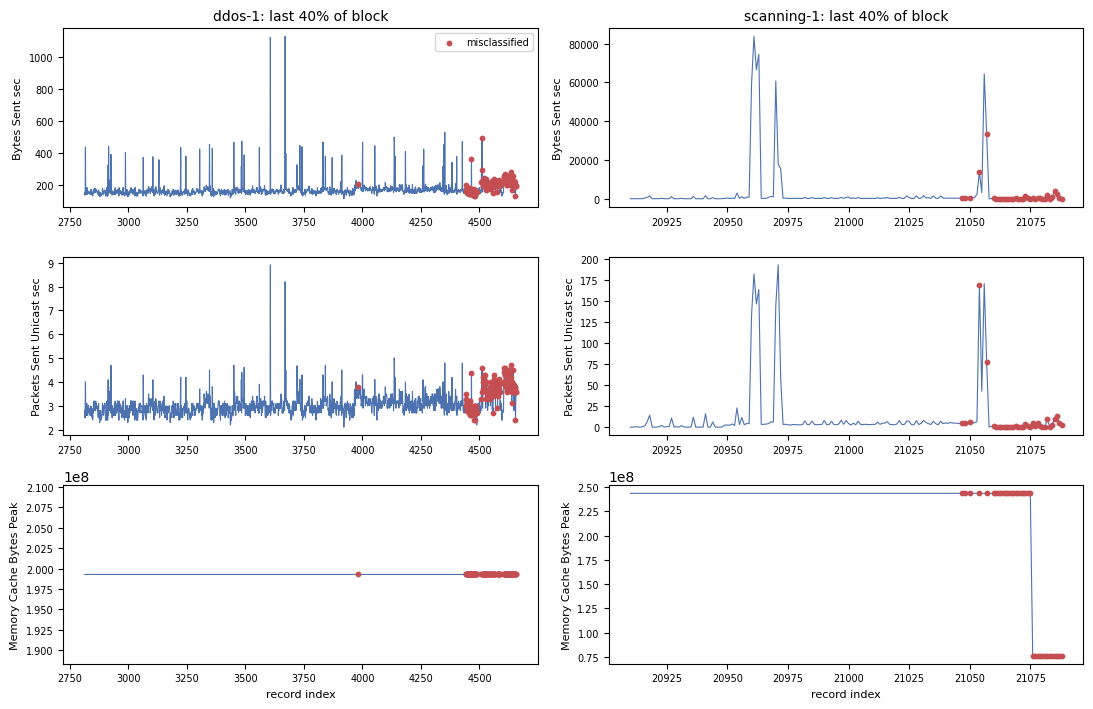

In [13]:
# C4b: block-end review without Logistic Regression; shifts scaled by the whole block's SD
er2 = er[er.model != 'LR']
print('Mean errors per run, by true class (Logistic Regression excluded):')
print((er2.groupby(['config', 'model', 'true']).size() / n_seeds).unstack('true').fillna(0).round(1).to_string())
print('\nWhat the errors are predicted as:'); print(er2.groupby(['true', 'predicted']).size().unstack(fill_value=0).to_string())
print(f"\nShare of errors in the last 5% of their block: {(er2.position_in_block >= 0.95).mean():.1%}; "
      f"within the last 50 records: {(er2.records_from_block_end < 50).mean():.1%}")
print('Error records by block:'); print(er2.groupby('block').record_index.agg(['nunique', 'min', 'max']).to_string())

rows = []
for c, segs in SEG.items():
    for k, s in enumerate(segs):
        if len(s) < 40: continue
        b = f'{c}-{k+1}'; mid = s[int(.4 * len(s)): int(.6 * len(s))]; end = s[-max(10, int(.05 * len(s))):]
        sd = Xr.loc[s, FEAT_CMP].std().replace(0, np.nan)
        d = ((Xr.loc[end, FEAT_CMP].median() - Xr.loc[mid, FEAT_CMP].median()) / sd).dropna()
        closer = ((Xr.loc[end, FEAT_CMP].median() - normal_med).abs() < (Xr.loc[mid, FEAT_CMP].median() - normal_med).abs())
        rows.append(dict(block=b, records=len(s), end_records=len(end), error_records=int(er2[er2.block == b].record_index.nunique()),
                         median_abs_shift_SD=round(float(d.abs().median()), 2),
                         share_features_closer_to_normal=round(float(closer.mean()), 2) if c != 'normal' else np.nan,
                         largest_shifts_SD='; '.join(f"{f.split(') ')[-1]} {v:+.2f}" for f, v in d.reindex(d.abs().sort_values(ascending=False).index[:3]).items())))
bt2 = pd.DataFrame(rows); bt2.to_csv(f'{OUT}/C4b_block_middle_vs_end_noLR.csv', index=False)
print('\nMiddle (40-60%) vs end (last 5%) of each block; shift in SDs of the whole block:'); print(bt2.to_string(index=False))

top_blocks = er2.groupby('block').record_index.nunique().sort_values(ascending=False).index[:2]
err_ids = set(er2.record_index)
fig, axes = plt.subplots(len(show), len(top_blocks), figsize=(5.5 * len(top_blocks), 2.4 * len(show)), squeeze=False)
for j, b in enumerate(top_blocks):
    c, k = b.rsplit('-', 1); s = SEG[c][int(k) - 1]; s = s[int(.6 * len(s)):]
    for r, f in enumerate(show):
        ax = axes[r, j]; v = Xr.loc[s, f].values; e = np.array([i in err_ids for i in s])
        ax.plot(s, v, lw=.8, color='#4C72B0'); ax.scatter(np.array(s)[e], v[e], s=10, color='#C44E52', zorder=3, label='misclassified')
        if r == 0: ax.set_title(f'{b}: last 40% of block', fontsize=10)
        ax.set_ylabel(f.split(') ')[-1], fontsize=8); ax.tick_params(labelsize=7)
axes[0, 0].legend(fontsize=7); [a.set_xlabel('record index', fontsize=8) for a in axes[-1]]
plt.tight_layout(); plt.savefig(f'{OUT}/C4b_block_end_stress_test_noLR.png', dpi=300); plt.show()

In [12]:
# C5: training-only feature selection as the main result; the 9- and 10-feature sets are comparisons from earlier experiments
if HAVE_PREV:
    sm = pd.read_csv(f'{PREV}/summary_mean_sd.csv'); sm['config'] = sm['config'].astype(str)
    order = ['reselect', '9', '10']; lab = {'reselect': 'Training-only selection (main)', '9': 'Original 9 (comparison)', '10': 'Original 9 + MCL (comparison)'}
    acc = sm.assign(v=lambda d: d.apply(lambda r: f"{r.test_acc_mean:.2f} ± {r.test_acc_sd:.2f}", axis=1)).pivot(index='model', columns='config', values='v')[order].rename(columns=lab)
    f1 = sm.assign(v=lambda d: d.apply(lambda r: f"{r.test_f1_mean:.3f} ± {r.test_f1_sd:.3f}", axis=1)).pivot(index='model', columns='config', values='v')[order].rename(columns=lab)
    mo = [m for m in MODELS if m in acc.index]
    print('Test accuracy (%), mean ± SD over 5 seeds (same test set):'); print(acc.reindex(mo).to_string())
    print('\nTest macro-F1:'); print(f1.reindex(mo).to_string())
    acc.reindex(mo).to_csv(f'{OUT}/C5_main_table_accuracy.csv'); f1.reindex(mo).to_csv(f'{OUT}/C5_main_table_macroF1.csv')
rs = pd.read_csv(f'{OUT}/reselection_report.csv', index_col=0)
print('\nTraining-only selected features (main feature set):')
print(rs[rs.decision == 'kept'][['rf_importance', 'F_train']].round(3).to_string())
print('\nOrigin of the comparison sets: the 9 features (and Memory Commit Limit) were chosen in the earlier experiments,'
      '\nwhose selection used the full dataset; they are reported for comparison only.')

Test accuracy (%), mean ± SD over 5 seeds (same test set):
config Training-only selection (main) Original 9 (comparison) Original 9 + MCL (comparison)
model                                                                                      
LR                       97.94 ± 0.00            63.49 ± 0.00                  97.89 ± 0.00
DT                       99.80 ± 0.02            99.42 ± 0.01                  99.44 ± 0.05
RF                       99.69 ± 0.00            98.94 ± 0.89                  99.48 ± 0.32
XGB                      99.67 ± 0.00            99.59 ± 0.02                  99.63 ± 0.02
LGBM                     97.16 ± 0.00            97.63 ± 0.00                  97.94 ± 0.00
MLP                      99.67 ± 0.03            99.65 ± 0.02                  99.67 ± 0.03
TabNet                   99.60 ± 0.12            99.47 ± 0.40                  99.66 ± 0.03
FT                       99.61 ± 0.17            99.42 ± 0.50                  99.69 ± 0.01

Test macro-F1:
confi

In [14]:
# C6: is there any record that the blocks are separate sessions?
import re
pat = re.compile(r'timestamp|date|session|(^|[^a-z])ts([^a-z]|$)|uid|elapsed|process id|id process', re.I)
print('Columns in the train/test file that could carry time or session information:', [c for c in raw.columns if pat.search(c)])
marker_cols = [c for c in ['Process_ID Process', 'Process_Creating Process ID', 'Process_Elapsed_Time'] if c in df.columns]
rows = []
for c, segs in SEG.items():
    for k, s in enumerate(segs):
        r = dict(block=f'{c}-{k+1}', first_row=int(s[0]), last_row=int(s[-1]), records=len(s))
        for col in marker_cols:
            v = df.loc[s, col].values
            r[f'{col}: distinct'] = len(np.unique(v)); r[f'{col}: first'] = v[0]; r[f'{col}: last'] = v[-1]
        rows.append(r)
sess = pd.DataFrame(rows).sort_values('first_row'); sess.to_csv(f'{OUT}/C6_block_session_markers.csv', index=False)
print('\nProcess counters per block, in file order (a new process ID or a reset of elapsed time at a block boundary'
      '\nwould suggest a new collection run; identical or continuing values suggest the same run):')
print(sess.to_string(index=False))

full = glob.glob('/content/**/windows10_dataset*.csv', recursive=True)
if not full:
    print('\nFull TON_IoT Windows 10 file not uploaded. The TON_IoT paper (Moustafa et al.) says records were labelled by'
          '\nmatching a "ts" timestamp, but the train/test file has no timestamp, so sessions cannot be confirmed from it.')
else:
    fd = pd.read_csv(full[0], low_memory=False); print('\nFull file:', full[0], fd.shape)
    tcols = [c for c in fd.columns if pat.search(c)]; print('Time/session-like columns in full file:', tcols)
    common = [c for c in FEATS_ALL if c in fd.columns]
    key = lambda d: pd.util.hash_pandas_object(d[common].apply(pd.to_numeric, errors='coerce').round(4).fillna(-1), index=False).values
    fk = pd.Series(range(len(fd)), index=key(fd)); fk = fk[~fk.index.duplicated()]
    match = pd.Series(key(raw.loc[df.index]), index=df.index).map(fk)
    print(f'Train/test records matched to the full file: {match.notna().mean():.1%}')
    if tcols and match.notna().any():
        tcol = tcols[0]; tvals = fd[tcol].values
        out = []
        for c, segs in SEG.items():
            for k, s in enumerate(segs):
                mm = match.loc[s].dropna().astype(int)
                if len(mm): out.append(dict(block=f'{c}-{k+1}', matched=len(mm), first=tvals[mm.iloc[0]], last=tvals[mm.iloc[-1]]))
        tb = pd.DataFrame(out); tb.to_csv(f'{OUT}/C6_block_times_full_file.csv', index=False); print(tb.to_string(index=False))
print('\nIf the blocks cannot be tied to separate sessions, the paper should state that the study does not establish'
      '\nperformance on independent sessions (Prof. Abouali, check 6).')

Columns in the train/test file that could carry time or session information: ['Process_Elapsed_Time', 'Process_Creating Process ID', 'Process_ID Process']

Process counters per block, in file order (a new process ID or a reset of elapsed time at a block boundary
would suggest a new collection run; identical or continuing values suggest the same run):
      block  first_row  last_row  records  Process_ID Process: distinct  Process_ID Process: first  Process_ID Process: last  Process_Creating Process ID: distinct  Process_Creating Process ID: first  Process_Creating Process ID: last  Process_Elapsed_Time: distinct  Process_Elapsed_Time: first  Process_Elapsed_Time: last
      dos-1          0        49       50                             1                          0                         0                                      1                                   0                                  0                               1                            0                           0

In [15]:
# C7: statistics. The five seeds share ONE test set, so seed SD measures training randomness only, not test-set uncertainty.
# Here: bootstrap intervals that resample CONTIGUOUS chunks of test records (moving-block bootstrap, within each class),
# compared with the usual record-by-record bootstrap (chunk length 1). Treat as exploratory.
if not HAVE_PREV:
    print('Upload rerun_results.zip to run this check.')
else:
    Pp = dict(np.load(f'{PREV}/test_predictions.npz')); seeds_prev = sorted({int(k.split('|')[1]) for k in Pp})
    cls_pos = [np.where(y_te == i)[0] for i in range(len(CLASSES))]   # each class's test records, already in record order
    rng = np.random.default_rng(1); B = 2000

    def block_boot(v, L):
        means = np.zeros(B)
        for pos in cls_pos:
            s = v[pos]; n = len(s); l = min(L, n); k = int(np.ceil(n / l))
            cs = np.concatenate([[0], np.cumsum(s)])
            st = rng.integers(0, n - l + 1, (B, k))
            means += (cs[st + l] - cs[st]).sum(1) / (k * l) * n
        return means / len(v)

    rows = []
    for cfg in ['reselect', '9', '10']:
        corr = {m: np.mean([Pp[f'{cfg}|{s}|{m}'] == y_te for s in seeds_prev], axis=0) for m in MODELS if f'{cfg}|{seeds_prev[0]}|{m}' in Pp}
        for m, v in corr.items():
            for L in [1, 50, 200]:
                b = block_boot(v, L); rows.append(dict(config=cfg, quantity=f'{m} accuracy', chunk=L, estimate=100 * v.mean(),
                                                       ci_low=100 * np.percentile(b, 2.5), ci_high=100 * np.percentile(b, 97.5)))
        for other in ['RF', 'XGB', 'LGBM', 'MLP']:
            if 'FT' in corr and other in corr:
                d = corr['FT'] - corr[other]
                for L in [1, 50, 200]:
                    b = block_boot(d, L); rows.append(dict(config=cfg, quantity=f'FT − {other}', chunk=L, estimate=100 * d.mean(),
                                                           ci_low=100 * np.percentile(b, 2.5), ci_high=100 * np.percentile(b, 97.5)))
    bb = pd.DataFrame(rows); bb.to_csv(f'{OUT}/C7_block_bootstrap.csv', index=False)
    bb['95% CI'] = bb.apply(lambda r: f'[{r.ci_low:.2f}, {r.ci_high:.2f}]', axis=1)
    view = bb[bb.config == 'reselect'].pivot(index='quantity', columns='chunk', values='95% CI')
    view.columns = ['record-by-record (chunk 1)', 'chunks of 50 records', 'chunks of 200 records']
    print('Training-only feature set: accuracy and FT differences (percentage points), averaged over seeds, with 95% intervals:')
    print(view.to_string())
    print('\nWider intervals with longer chunks show how much the usual bootstrap understates uncertainty when neighbouring'
          '\nrecords are similar. Differences whose interval includes 0 should be reported as not distinguishable.')

Training-only feature set: accuracy and FT differences (percentage points), averaged over seeds, with 95% intervals:
                record-by-record (chunk 1) chunks of 50 records chunks of 200 records
quantity                                                                             
DT accuracy                 [99.66, 99.92]      [99.79, 100.00]        [99.78, 99.83]
FT accuracy                 [99.45, 99.76]      [99.48, 100.00]        [99.61, 99.62]
FT − LGBM                     [2.00, 2.91]         [0.24, 4.31]         [-0.08, 3.97]
FT − MLP                    [-0.10, -0.02]        [-0.13, 0.02]        [-0.08, -0.03]
FT − RF                     [-0.12, -0.05]        [-0.15, 0.00]        [-0.09, -0.08]
FT − XGB                     [-0.11, 0.00]        [-0.14, 0.04]        [-0.08, -0.04]
LGBM accuracy               [96.66, 97.63]       [95.29, 99.58]        [95.50, 99.69]
LR accuracy                 [97.49, 98.34]       [95.86, 99.75]        [95.91, 99.79]
MLP accuracy           

In [16]:
# C10: reproducibility package -> /content/release (add the two notebooks, then upload the folder to GitHub)
import shutil, importlib, platform
REL = os.environ.get('RELEASE_DIR', '/content/release'); os.makedirs(f'{REL}/results', exist_ok=True); os.makedirs(f'{REL}/checks', exist_ok=True)
for f in ['settings.json', 'feature_sets.json', 'split_and_cleaning.json', 'data_accounting.csv', 'split_sizes.csv', 'reselection_report.csv']:
    if os.path.exists(f'{OUT}/{f}'): shutil.copy(f'{OUT}/{f}', REL)
for f in glob.glob(f'{OUT}/C*_*') + glob.glob(f'{OUT}/*record_ids.csv'): shutil.copy(f, f'{REL}/checks')
if HAVE_PREV:
    for f in glob.glob(f'{PREV}/*'): shutil.copy(f, f'{REL}/results')
vers = {m: getattr(importlib.import_module(m), '__version__', '?') for m in ['numpy', 'pandas', 'sklearn', 'scipy', 'torch', 'xgboost', 'lightgbm', 'pytorch_tabnet']}
files = sorted(os.path.relpath(p, REL) for p in glob.glob(f'{REL}/**/*', recursive=True) if os.path.isfile(p))
readme = f"""# Leakage-aware evaluation on TON_IoT Windows 10: code and results

Revision materials for MDPI Analytics manuscript analytics-4589312.

## Data
The dataset is not redistributed. Download `Train_Test_Windows_10.csv` from the official TON_IoT page:
https://research.unsw.edu.au/projects/toniot-datasets

## How to reproduce
1. Open `revision_rerun.ipynb` in Google Colab (T4 GPU), upload `Train_Test_Windows_10.csv`, run all cells in order.
   It produces every file in `results/`.
2. Open `revision_checks.ipynb`, upload the CSV and `rerun_results.zip`, run all cells. It produces `checks/`.

## Protocol
Raw file (21,104 x 126) -> text-to-numeric (unparseable cells set to 0) -> MITM removed (21,089) -> per-class split in
record order 70/10/20 (14,759 / 2,109 / 4,221) -> fitted on training rows only: near-constant filter (104), 99th-percentile
caps, correlation filter (78), feature reselection, standard scaling -> 8 models x 3 feature sets x 5 seeds (42-46),
tuning and early stopping on validation only -> single test evaluation.
Exact record IDs per split: `checks/split_record_ids.csv`; held-out-block splits: `checks/heldout_block_record_ids.csv`.

## Environment
Python {platform.python_version()}; {', '.join(f'{k} {v}' for k, v in vers.items())}; rtdl_revisiting_models 0.0.2; Google Colab T4 GPU.

## Files
""" + '\n'.join(f'- `{f}`' for f in files + ['revision_rerun.ipynb (add)', 'revision_checks.ipynb (add)'])
open(f'{REL}/README.md', 'w').write(readme)
print(readme)

# Leakage-aware evaluation on TON_IoT Windows 10: code and results

Revision materials for MDPI Analytics manuscript analytics-4589312.

## Data
The dataset is not redistributed. Download `Train_Test_Windows_10.csv` from the official TON_IoT page:
https://research.unsw.edu.au/projects/toniot-datasets

## How to reproduce
1. Open `revision_rerun.ipynb` in Google Colab (T4 GPU), upload `Train_Test_Windows_10.csv`, run all cells in order.
   It produces every file in `results/`.
2. Open `revision_checks.ipynb`, upload the CSV and `rerun_results.zip`, run all cells. It produces `checks/`.

## Protocol
Raw file (21,104 x 126) -> text-to-numeric (unparseable cells set to 0) -> MITM removed (21,089) -> per-class split in
record order 70/10/20 (14,759 / 2,109 / 4,221) -> fitted on training rows only: near-constant filter (104), 99th-percentile
caps, correlation filter (78), feature reselection, standard scaling -> 8 models x 3 feature sets x 5 seeds (42-46),
tuning and early stopping on valida

In [17]:
# Last cell: zip and download the check results and the release folder
import shutil
z1 = shutil.make_archive(OUT.rstrip('/'), 'zip', OUT)
z2 = shutil.make_archive(REL.rstrip('/'), 'zip', REL) if os.path.exists(REL) else None
print('Created', z1, z2)
try:
    from google.colab import files
    files.download(z1)
    if z2: files.download(z2)
except Exception as e:
    print('Download from the Files panel:', e)

Created /content/checks_results.zip /content/release.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>